# 03 · The Full Pipeline: Parse → Filter → Retrieve → Personalize → Answer

**Project:** AI-Powered Semantic Product Discovery & Shopping Concierge · **Author:** Maaz Amjad

## Problem
Shoppers write requests like *"quiet portable countertop ice maker under $150"*. A useful assistant must respect the
hard limits exactly, understand the descriptive part, adapt to the shopper, and explain its picks **without inventing
facts**.

## Data
The 10,000-product Appliances catalog (Amazon Reviews 2023), its BGE embeddings, 24,103 interactions from 3,995 users,
and the 25 benchmark queries with their cached Gemini parses.

## Approach
`src/pipeline.respond()` chains the modules: the LLM **extracts** constraints (`parse.py`), Python **enforces** them
(`filters.py`), BGE retrieves inside the allowed set (`retrieve.py`, filter-first), a weighted score re-ranks for the
user (`personalize.py`), and the LLM writes a structured answer that a deterministic validator checks (`generate.py`).
This notebook runs with `max_calls=0`: every LLM response comes from the cache, so it is free and reproducible.

## Results (details below)
- Hard limits are parsed by the LLM and enforced in Python: every recommended product obeys them.
- When nothing matches, the answer says so and suggests which limit to relax, without any LLM call.
- Personalization re-orders the allowed products for returning users and falls back cleanly for new users.
- 22/22 benchmark answers are grounded (21 on the first try); the validator caught one invented product ID.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import load_config, set_seed
from src.data import load_interactions
from src.evaluate import load_parsed, load_queries, to_parsed_query
from src.generate import Answer, Rec, validate_answer
from src.personalize import Weights, pick_users, rank
from src.pipeline import load_resources, respond

set_seed(42)
cfg = load_config()
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#e8833a", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})
pd.set_option("display.max_colwidth", 70)

res = load_resources(cfg, max_calls=0)   # max_calls=0: an uncached LLM call raises instead of spending quota
queries = load_queries().set_index("query_id")
parsed = load_parsed().set_index("query_id")
print(f"catalog {res.catalog.shape}, user profiles {len(res.profiles)}, brands {len(res.brands)}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

catalog (10000, 9), user profiles 3995, brands 2315


## 1. One request end to end
q02 is a test query with a price limit and descriptive wishes (*quiet*, *portable*, *countertop*).

In [2]:
qid = "q02"
text = queries.text[qid]
out = respond(text, res, parsed=to_parsed_query(parsed.loc[qid]))
print("Request:", text)
print("Parsed :", out.parsed_query.model_dump(exclude_defaults=True))
print(f"Products satisfying the hard limits: {out.flags['n_satisfying']} | excluded only for a missing price: "
      f"{out.flags['price_excluded']}")
display(out.ranked.merge(res.catalog[["product_id", "title", "price"]], on="product_id")
        [["rank", "title", "price", "cosine", "s_sem", "s_pop", "final"]].round(3))


Request: quiet portable countertop ice maker under $150
Parsed : {'semantic_query': 'quiet portable countertop ice maker', 'max_price': 150.0, 'category': 'Ice Makers'}
Products satisfying the hard limits: 102 | excluded only for a missing price: 191


,rank,title,price,cosine,s_sem,s_pop,final
0,1,"Countertop Ice Maker, FREE VILLAGE Ice Maker Machine for Counterto...",110.49,0.855,0.994,0.656,0.971
1,2,"Ice Makers Countertop, Self-Cleaning Function, Portable Electric I...",69.99,0.857,1.000,0.533,0.969
2,3,"Ice Maker Machine for Countertop, 9 Ice Cubes Ready in 6 Minutes, ...",93.04,0.840,0.932,0.572,0.908
3,4,Ice Maker Machine for Countertop - Portable Ice Cube Maker deliver...,129.99,0.838,0.924,0.369,0.887
4,5,Antarctic Star Countertop Ice Maker Portable Ice Machine with Hand...,47.99,0.831,0.896,0.546,0.872


**Insight.** The parser turned *"under $150"* into `max_price = 150` and recognised the product type as the catalog
category *Ice Makers*, while *quiet*, *portable* and *countertop* stayed in the semantic query, as the spec requires.
Python then left 102 products that satisfy the limits; 191 more ice makers have no listed price, so they are excluded
(only because a price filter is active). Every product in the top 5 costs under $150, and all five are countertop
machines. Cosine similarities are packed into a narrow band (0.83 to 0.86), which is why `s_sem` is min-max
normalized inside the pool before it is mixed with popularity (here a new user, so the personal weight is 0).

In [3]:
print(out.answer.text)
print("\nGrounding errors:", out.answer.errors or "none", "| fallback:", out.answer.fallback)
print("Stage timings (ms):", {k: round(v, 1) for k, v in out.timings_ms.items()})


Here are the best quiet, portable countertop ice makers priced under $150 that fit your requirements.
1. Countertop Ice Maker, FREE VILLAGE Ice Maker Machine for Countertop ... ($110.49): This portable ice maker operates at less than 45 decibels, features a self-cleaning function, and costs $110.49.
2. Ice Makers Countertop, Self-Cleaning Function, Portable Electric Ice Cube Maker ... ($69.99): It offers quiet operation, a portable design with self-cleaning, and is priced at $69.99.
3. Ice Maker Machine for Countertop, 9 Ice Cubes Ready in ... ($93.04): This compact ice maker runs at a very low noise level below 35dB and costs $93.04.
4. Ice Maker Machine for Countertop - Portable Ice Cube Maker ... ($129.99): A portable countertop ice machine with a quiet <45dB noise level, priced at $129.99.
5. Antarctic Star Countertop Ice Maker Portable Ice Machine with Handle,Self-Cleaning ... ($47.99): This ultra-quiet portable ice maker runs at under 35dB and is priced at $47.99.

Grounding erro

**Insight.** Each reason uses facts from the product data (noise level in dB, self-cleaning) and quotes each price
exactly as listed; the validator found nothing to reject. Titles and prices in the rendered list come from the catalog,
not from the LLM, so they cannot be misquoted. Generation is the slow stage: about 6 s per answer when the call is live
(section 5); here it is a cache hit. Retrieval plus ranking takes well under 0.5 s on a CPU.

## 2. When nothing matches
q25 asks for an *LG freezer under $50*, which the catalog does not contain.

In [4]:
qid = "q25"
out25 = respond(queries.text[qid], res, parsed=to_parsed_query(parsed.loc[qid]))
print("Request:", queries.text[qid])
print("Parsed :", out25.parsed_query.model_dump(exclude_defaults=True))
print("\n" + out25.answer.text)
print("\nLLM calls used:", out25.answer.attempts)


Request: LG freezer under $50
Parsed : {'semantic_query': 'freezer', 'max_price': 50.0, 'category': 'Freezers', 'brand': 'LG'}

No products in the catalog match all of your constraints. Removing the category constraint would give 115 matching products.

LLM calls used: 0


**Insight.** No LLM is used on this path. Python counts how many products would remain if each limit were dropped
alone, and suggests the one that restores the most: without the *Freezers* category there are 115 LG products under
$50 (mostly parts and accessories). This is deterministic and cannot hallucinate a product that does not exist.

## 3. New shopper vs returning shopper
The same candidate pool for q02, ranked for a cold-start user and for each of the 8 experiment-A users (at least 10 past interactions). Only the ranking is recomputed; no LLM call is needed.

In [5]:
users = pick_users(load_interactions(), n=8, min_interactions=10, seed=cfg["seed"])
w = Weights.from_config(cfg)
cold = rank(out.candidates, None, w, catalog=res.catalog, embeddings=res.embeddings)
rows = []
for u in users:
    warm = rank(out.candidates, res.profiles[u], w, catalog=res.catalog, embeddings=res.embeddings)
    rows.append({"user": u[:8], "top10_overlap_with_cold": len(set(cold.head(10).row) & set(warm.head(10).row)) / 10,
                 "rank1_changed": warm.row.iat[0] != cold.row.iat[0]})
shift = pd.DataFrame(rows)
display(shift)

u = users[0]
warm = rank(out.candidates, res.profiles[u], w, catalog=res.catalog, embeddings=res.embeddings)
top = warm.head(5).merge(res.catalog[["product_id", "title"]], on="product_id")
top["cold_rank"] = top.row.map(dict(zip(cold.row, cold["rank"])))
display(top[["rank", "cold_rank", "title", "s_sem", "s_pers", "s_pop", "final"]].round(3))


,user,top10_overlap_with_cold,rank1_changed
0,AEFKZBHT,0.6,True
1,AFYCZCWF,0.6,True
2,AFYQH7QV,0.6,True
3,AGQY2K37,0.6,True
4,AH2MO6H4,0.5,True
5,AH7F5U5W,0.7,True
6,AHJYTHKL,0.5,True
7,AHYKYOVX,0.6,True


,rank,cold_rank,title,s_sem,s_pers,s_pop,final
0,1,2,"Ice Makers Countertop, Self-Cleaning Function, Portable Electric I...",1.000,0.308,0.533,0.804
1,2,1,"Countertop Ice Maker, FREE VILLAGE Ice Maker Machine for Counterto...",0.994,0.154,0.656,0.767
2,3,6,"COSTWAY Ice Maker Countertop, 26LBS/24H Portable Electric Ice Mach...",0.906,0.440,0.373,0.763
3,4,3,"Ice Maker Machine for Countertop, 9 Ice Cubes Ready in 6 Minutes, ...",0.932,0.238,0.572,0.740
4,5,25,"Oline Ice Maker Machine, Automatic Self-Cleaning Portable Electric...",0.821,0.499,0.683,0.734


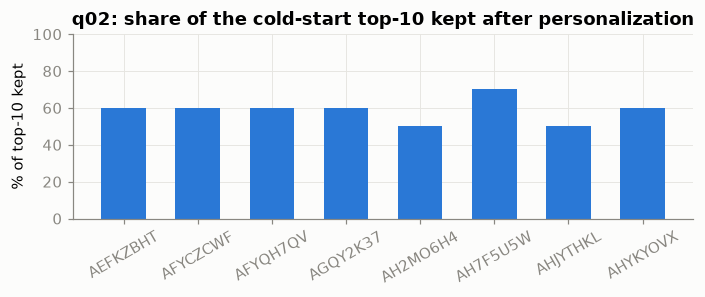

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.bar(shift.user, shift.top10_overlap_with_cold * 100, color=BLUE, width=0.6)
ax.set_ylim(0, 100); ax.set_ylabel("% of top-10 kept")
ax.set_title("q02: share of the cold-start top-10 kept after personalization")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()


**Insight.** Personalization changes the ranking, not just the scores: for every one of the 8 users the first
result changes, and only 50 to 70 % of the cold-start top 10 survives. Every result still obeys the price limit,
because personalization only re-orders the filter-first pool. In the example, an item ranked 25th for a new user moves
up to 5th because it is close to that user's history (`s_pers` 0.50). Whether that helps or hurts query relevance is
measured in `04_evaluation` (experiment A); on the next-item task (experiment B) the blended score beats popularity.

## 4. The grounding validator catches invented facts
We hand the validator a fake answer for q02 with an invented product ID, a wrong price and a brand that is not in the results.

In [7]:
items = res.catalog.iloc[out.ranked.row.to_numpy()].reset_index(drop=True)
real = items.iloc[0]
fake = Answer(summary="Best pick at $9.99, better than any Bosch model.",
              recommendations=[Rec(product_id="B000FAKE01", reason="Silent."),
                               Rec(product_id=real.product_id, reason=f"Only ${real.price:.2f}.")])
for err in validate_answer(fake, items, {150.0}, res.brands, query=text, max_recs=5):
    print("-", err)


- unknown product id B000FAKE01
- price $9.99 is not a listed price
- brand BOSCH is not in the product data


**Insight.** All three injected errors are caught: the invented product ID, a price that no retrieved product has,
and a brand (*Bosch*) that is in the catalog but not among the results. The brand check matches capitalised mentions in
any case, so *Bosch* is caught even though the catalog spells it *BOSCH*. A first version matched the catalog spelling
exactly and missed this case; this demo exposed it, and it was fixed with a failing test first.

## 5. Generation over all 25 benchmark queries (spec 10.7)
Results saved by `python -m src.pipeline`; latency comes from the first, uncached run (`generation_validator_v1.csv`).

,count
answers via LLM,22
no-result answers (no LLM),3
grounded on first try,21
grounded in the end,22
template fallbacks,0
invented ids caught,1
price mismatches,0
brand mismatches,0
"LLM-written words, max",105


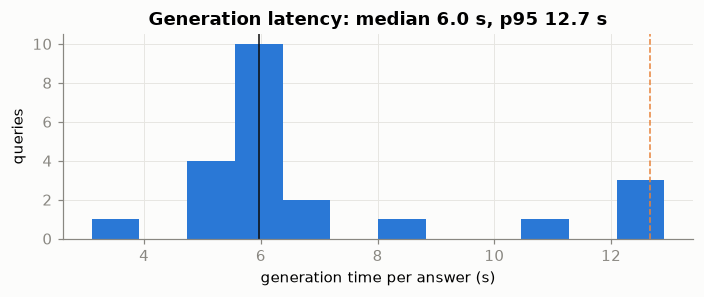

In [8]:
gen = pd.read_csv(PROJECT_ROOT / "eval" / "results" / "generation.csv")
v1 = pd.read_csv(PROJECT_ROOT / "eval" / "results" / "generation_validator_v1.csv")
llm = gen[gen.fallback.fillna("") != "no_result"]
summary = pd.Series({
    "answers via LLM": len(llm), "no-result answers (no LLM)": int((gen.fallback == "no_result").sum()),
    "grounded on first try": int(llm.grounded_first_try.sum()), "grounded in the end": int(llm.grounded_final.sum()),
    "template fallbacks": int((gen.fallback == "template").sum()),
    "invented ids caught": int(gen.bad_ids.sum()), "price mismatches": int(gen.bad_prices.sum()),
    "brand mismatches": int(gen.bad_brands.sum()), "LLM-written words, max": int(llm.llm_words.max()),
})
display(summary.to_frame("count"))
lat = v1[v1.fallback.fillna("") != "no_result"].generate_ms / 1000
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.hist(lat, bins=12, color=BLUE)
ax.axvline(lat.median(), color=INK, lw=1); ax.axvline(lat.quantile(0.95), color=ORANGE, lw=1, ls="--")
ax.set_xlabel("generation time per answer (s)"); ax.set_ylabel("queries")
ax.set_title(f"Generation latency: median {lat.median():.1f} s, p95 {lat.quantile(0.95):.1f} s")
plt.tight_layout(); plt.show()


**Insight.** Over the 22 queries that reach the LLM, 21 answers pass the validator on the first try and all 22
after at most one regeneration; the template fallback was never needed. The one rejected answer (dev query q04)
cited a product ID that does not exist, which is exactly the hallucination the validator is for. The LLM-written
text stays under the 120-word limit (max 105 words). Generation latency (median about 6 s, p95 about 13 s) dominates
end-to-end time and exceeds the 6 s p95 target, mainly because of the free-tier Gemini endpoint.